#Surface by surface simulation

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from utilities import make_grid, angular_spectrum, pupil, plot_field
from ilumination import source_field, source_spectrum, mirror_pupil

###Source

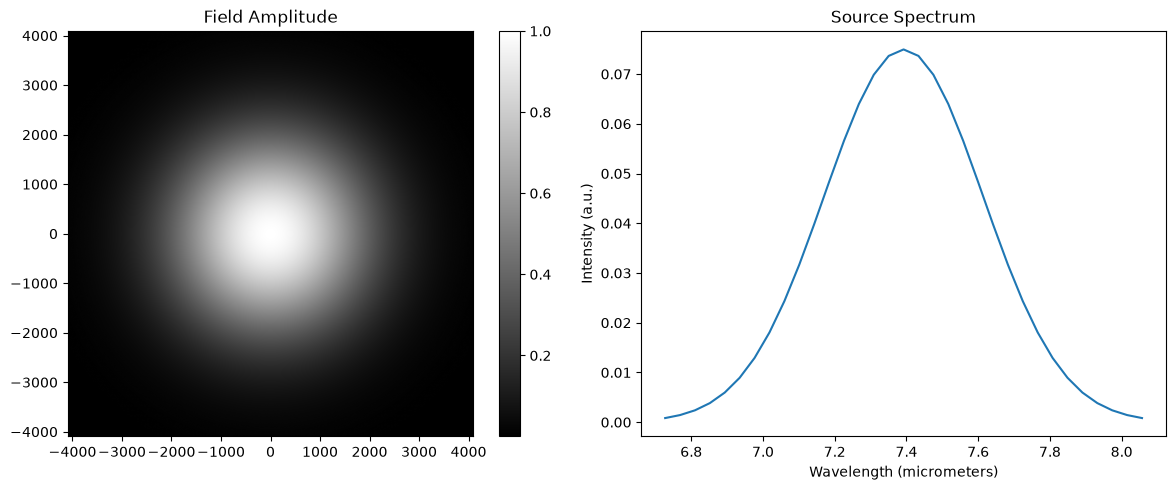

In [2]:
central_lam = 0.850 # central wavelength in micrometers
fwhm = 0.06  # full width at half maximum in micrometers
n = np.array([4096, 4096])
dx, dy = 2, 2
w0 = 2e3

X, Y = make_grid(n, dx, dy)
U_source = source_field(X, Y, central_lam, w0)
S_source = source_spectrum(central_lam, fwhm, n_k=33)

#Plot field amplitude and phase
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(np.abs(U_source), extent=[X.min(), X.max(), Y.min(), Y.max()], cmap='gray')
plt.title('Field Amplitude')
plt.colorbar()

plt.subplot(1, 2, 2)
plt.plot(S_source[0], S_source[1])
plt.title('Source Spectrum')
plt.xlabel('Wavelength (micrometers)')
plt.ylabel('Intensity (a.u.)')

plt.tight_layout()
plt.show()

###Just before mirror

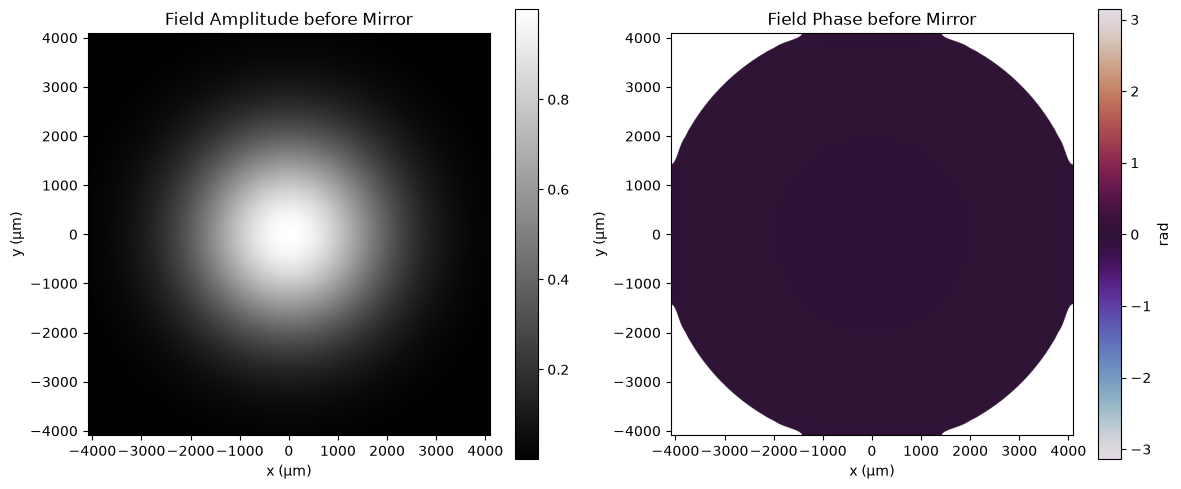

In [3]:
z_M1 = 50e3  # distance to mirror in micrometers

U_M1_ = angular_spectrum(U_source, dx=dx, dy=dy, z=z_M1, lam=central_lam)

plot_field(U_M1_, X, Y, 'before Mirror', z=z_M1, lam=central_lam)

###Just after mirror

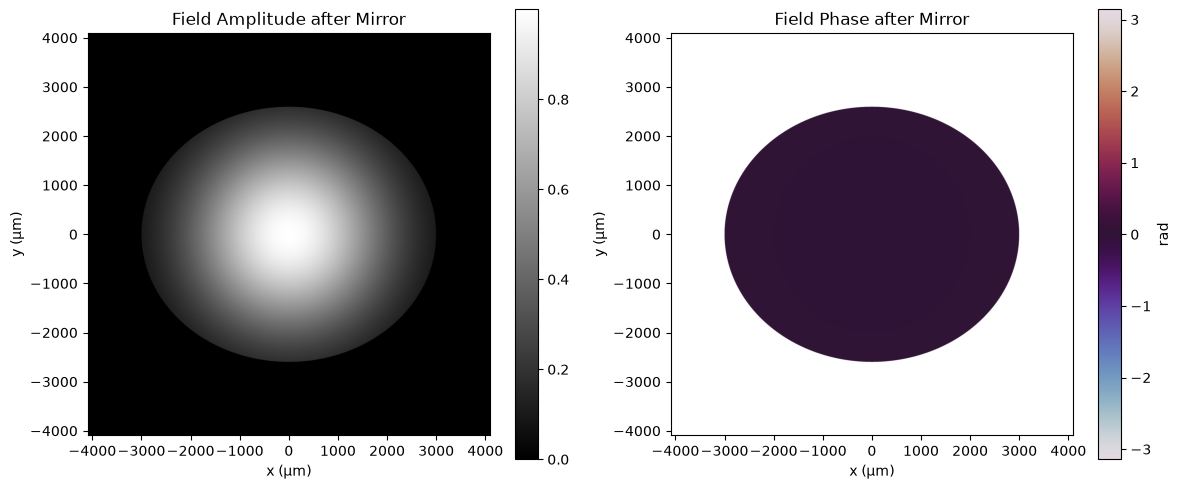

In [4]:
M1_r = 3e3 # Mirror 1 radius in micrometers
M1_theta = 30
P_M1 = mirror_pupil(X, Y, M1_r, M1_theta)

U_M1 = U_M1_ * P_M1

plot_field(U_M1, X, Y, 'after Mirror', z=z_M1, lam=central_lam)

###Just before sample

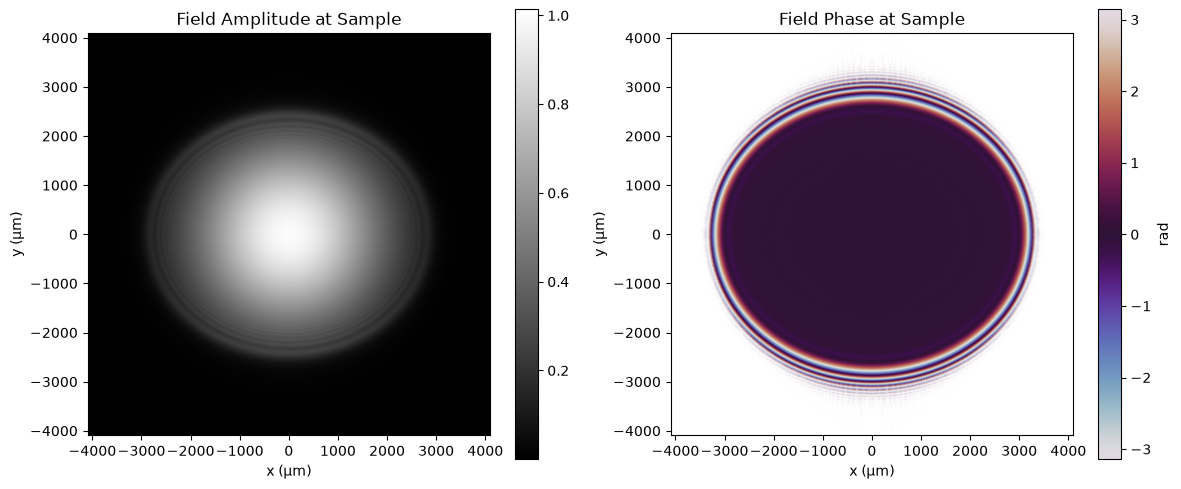

In [5]:
z_sample = 50e3  # distance to sample in micrometers
U_sample = angular_spectrum(U_M1, dx=dx, dy=dy, z=z_sample, lam=central_lam)

plot_field(U_sample, X, Y, 'at Sample', z=z_M1 + z_sample, lam=central_lam)

###Just after sample

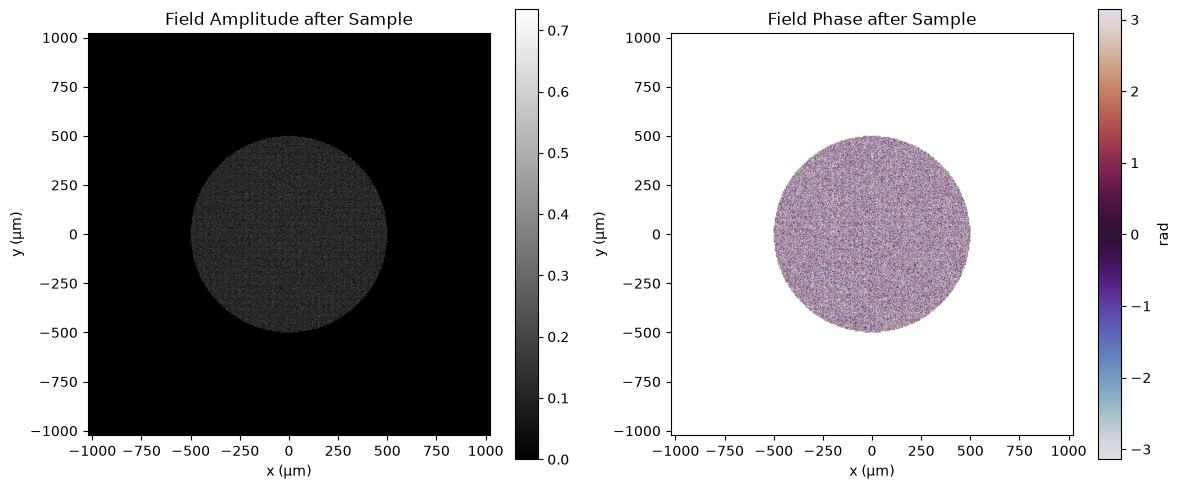

In [6]:
import numpy as np
from doppler_scattering import scattering_vector, mie_amplitude, object_amplitudes, field_after_sample
from utilities import crop

from pathlib import Path

DPD = Path.cwd().parents[1] / "DPD tissue" / "code"

trajs = [dict(np.load(DPD / "runs" / f"cell_{k}" / "traj.npz")) for k in range(4)]
layout = dict(np.load(DPD / "layout.npz"))
q, theta_s = scattering_vector()                    # n = 1.36: |q| ≈ 19.3 µm⁻¹
S_name = {"nucleus": mie_amplitude(1.0, 1.39, 1.36, theta_s),
          "mitochondrion": mie_amplitude(0.44, 1.41, 1.36, theta_s),
          "vesicle": mie_amplitude(0.25, 1.40, 1.36, theta_s)}
amps = object_amplitudes(layout, trajs, S_name)      # once
s = slice(n[0]//2 - 512, n[0]//2 + 512)            # 1024 x 1024 px = 2 mm, contains the 1 mm disk
U_ill, Xc, Yc = U_sample[s, s], X[s, s], Y[s, s]
U_after = field_after_sample(0, U_ill, Xc, Yc, layout, trajs, amps, q)

plot_field(U_after, Xc, Yc, 'after Sample', z=z_M1 + z_sample, lam=central_lam)

###Image plane (objective 2f-2f)

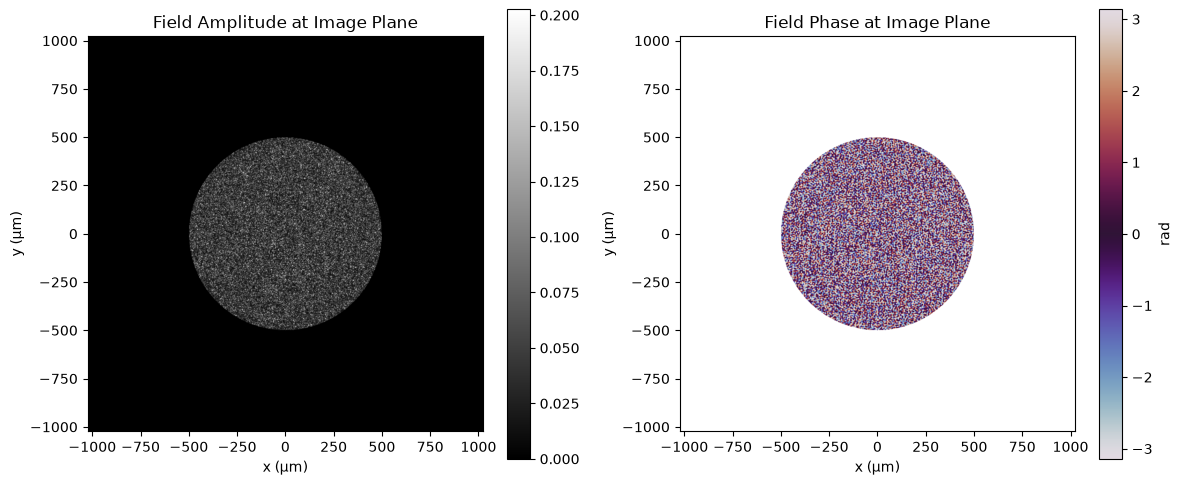

In [8]:
from collection import lens_transmitance
from utilities import fresnel_fft

f1, R1 = 75e3, 12.7e3          # objective focal length and radius (1-inch lens assumed)
R_IP = 500                     # field stop at the image plane

U_L1_, X1, Y1 = fresnel_fft(U_after, Xc, Yc, central_lam, 2*f1)     # just before objective
U_L1 = U_L1_ * lens_transmitance(X1, Y1, f1, central_lam, R1)        # just after objective
U_IP_, Xi, Yi = fresnel_fft(U_L1, X1, Y1, central_lam, 2*f1)        # image plane
U_IP = U_IP_ * pupil(Xi, Yi, R_IP)

plot_field(U_IP, Xi, Yi, 'at Image Plane')

###Camera (Fourier lens + biprism)

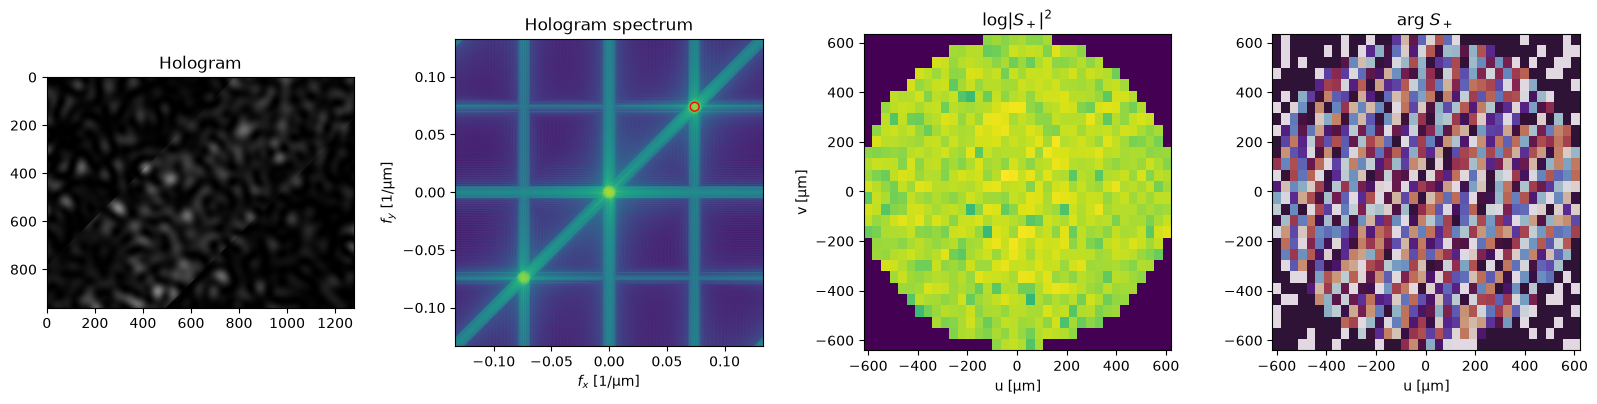

sideband pixels: 791


In [12]:
from collection import camera_hologram
from matplotlib.patches import Circle

f2 = 200e3
theta = 0.51 * np.radians(5)
d_B = 20e3
p = 3.75
xc = (np.arange(1280) - 640) * p
yc = (np.arange(960) - 480) * p
Lambda = central_lam / (2 * theta)
I = camera_hologram(U_IP, Xi, Yi, central_lam, f2, xc, yc, theta, d_B)

# Spectrum of the hologram and its frequency axes [1/µm]
F = np.fft.fftshift(np.fft.fft2(I - I.mean()))
fx = np.fft.fftshift(np.fft.fftfreq(I.shape[1], p))
fy = np.fft.fftshift(np.fft.fftfreq(I.shape[0], p))

# Carrier along the biprism normal and the sideband radius
c = np.array([np.cos(np.radians(45)), np.sin(np.radians(45))]) / Lambda
r_sb = 1.3 * R_IP / (central_lam * f2)

# Crop a box around the carrier, then mask it to a disk
ix = np.abs(fx - c[0]) <= r_sb
iy = np.abs(fy - c[1]) <= r_sb
FX, FY = np.meshgrid(fx[ix], fy[iy])
F_sb = F[np.ix_(iy, ix)] * (np.hypot(FX - c[0], FY - c[1]) <= r_sb)

# Fourier-plane coordinates mapped back to image-plane µm: u = λ f2 (f - c)
ext = central_lam * f2 * np.array([fx[ix][0] - c[0], fx[ix][-1] - c[0],
                                   fy[iy][0] - c[1], fy[iy][-1] - c[1]])

plt.figure(figsize=(16, 4.5))
plt.subplot(1, 4, 1); plt.imshow(I, cmap='gray'); plt.title('Hologram')
ax = plt.subplot(1, 4, 2)
plt.imshow(np.log10(np.abs(F)**2 + 1e-12), origin='lower',
           extent=[fx[0], fx[-1], fy[0], fy[-1]])
ax.add_patch(Circle(c, r_sb, fill=False, color='r'))
plt.xlabel(r'$f_x$ [1/µm]'); plt.ylabel(r'$f_y$ [1/µm]'); plt.title('Hologram spectrum')
plt.subplot(1, 4, 3)
plt.imshow(np.log10(np.abs(F_sb)**2 + 1e-12), origin='lower', extent=ext)
plt.xlabel('u [µm]'); plt.ylabel('v [µm]'); plt.title(r'$\log|S_+|^2$')
plt.subplot(1, 4, 4)
plt.imshow(np.angle(F_sb), cmap='twilight', origin='lower', extent=ext)
plt.xlabel('u [µm]'); plt.title(r'arg $S_+$')
plt.tight_layout(); plt.show()
print(f'sideband pixels: {np.count_nonzero(F_sb)}')

###Time series and field spectrum

Holograms: 100%|██████████| 1400/1400 [22:40<00:00,  1.03it/s]


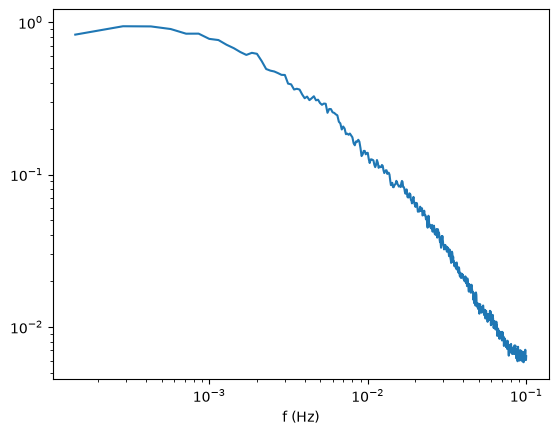

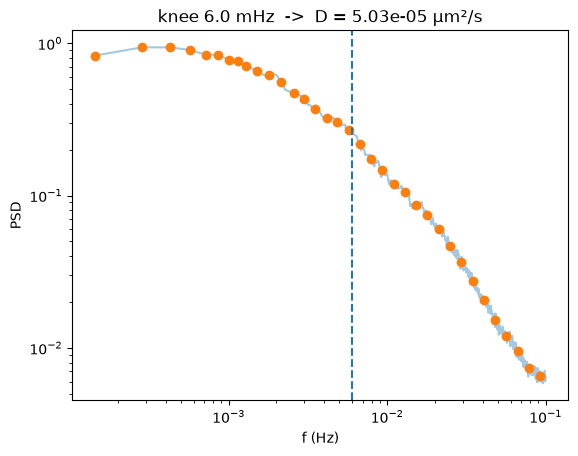

In [13]:
from spectrum import field_spectrum, log_bin, knee_frequency
from collection import sideband
from tqdm.auto import tqdm

n_frames = 1400
S = []
for k in tqdm(range(n_frames), desc='Holograms'):
    U_after = field_after_sample(k, U_ill, Xc, Yc, layout, trajs, amps, q)
    U_L1, X1, Y1 = fresnel_fft(U_after, Xc, Yc, central_lam, 2*f1)
    U_L1 *= lens_transmitance(X1, Y1, f1, central_lam, R1)
    U_IP, Xi, Yi = fresnel_fft(U_L1, X1, Y1, central_lam, 2*f1)
    U_IP *= pupil(Xi, Yi, R_IP)
    I = camera_hologram(U_IP, Xi, Yi, central_lam, f2, xc, yc, theta, d_B)
    S.append(sideband(I, p, Lambda, radius=1.3 * R_IP / (central_lam * f2)))   # whole sideband disk, every pixel
    
    # Checkpoint every 100 frames
    if (k + 1) % 100 == 0:
        np.save('S_checkpoint.npy', np.array(S))

S = np.array(S)                                      # (frames, pixels)
np.save('S_final.npy', S)

f, P = field_spectrum(S)
plt.loglog(f, P); plt.xlabel('f (Hz)'); plt.show()

fk = knee_frequency(f, P)
D = np.pi * fk / np.linalg.norm(q)**2              # |q| ≈ 19.3 µm⁻¹ in cytoplasm

plt.loglog(f, P, alpha=0.4)
plt.loglog(*log_bin(f, P), 'o')
plt.axvline(fk, ls='--')
plt.xlabel('f (Hz)'); plt.ylabel('PSD')
plt.title(f'knee {fk*1e3:.1f} mHz  ->  D = {D:.2e} µm²/s')
plt.show()